# Pendubot swing-up: a hands-on lecture on model predictive control

**Konstantinos Chatzilygeroudis · University of Patras**<br>
CloudPendulum workshop · 24 November 2026<br>
**SSQP: joint work with Nick Karydakis**

How can one motor swing up two links and catch them upright? We will build the
answer in small steps: understand the mechanism, express the task, construct an
optimizer, close the feedback loop, and test one design change.

By the end, you should be able to **explain each signal from a joint measurement
to the shoulder torque**, and support a tuning choice with motion and timing data.

## How to use this notebook

Each activity follows **predict → run → explain**. Make a prediction before
executing the cell; use the result to explain what changed. The examples are
complete and runnable, so you can return to a working starting point.
Expand the **discussion hints** after trying the questions.

| Core route | Time | What you will produce |
|---|---|---|
| 1. Read the robot, dynamics and costs | 0–5 min | A coordinate sketch and a prediction about the target |
| 2. Build model, costs and MPC | 5–13 min | A controller you can explain |
| 3. Run and inspect a baseline | 13–21 min | A recording, state traces and measured timings |
| 4. Change one factor and compare | 21–28 min | One controlled tuning experiment |
| 5. Test disturbance recovery | 28–30 min | A matched reference/pulse rollout and recovery evidence |

The six teaching figures are
embedded and visible when you open the notebook. Measured-result plots appear
after you run an experiment.

## Before we begin

Place this notebook beside **`pendubot.urdf`**. The numerical activities below
use NumPy and Matplotlib. The controller section additionally requires a
CloudPendulum kernel providing `ssqpy` and `pycloudpendulumbenchmark`.

The hardware experiment has a separate switch, initially disabled. Building a
model, defining a controller, and drawing figures do not start an experiment.
Later, set your assigned `CELL_ID` and `TOKEN_PATH` in the experiment settings.

Run the setup cell once. The two link lengths are read from the robot description
so that the geometry exercises and the model describe the same mechanism.

In [ ]:
import json
from pathlib import Path
from time import perf_counter
import xml.etree.ElementTree as ET

import numpy as np
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

URDF_PATH = "pendubot.urdf"
assert Path(URDF_PATH).is_file(), "Place pendubot.urdf beside the notebook."
robot_xml = ET.parse(URDF_PATH).getroot()
LINK_LENGTHS = np.array([
    np.linalg.norm(np.fromstring(robot_xml.find("joint[@name='joint2']/origin").get("xyz"), sep=" ")),
    np.linalg.norm(np.fromstring(robot_xml.find("joint[@name='tip_link']/origin").get("xyz"), sep=" ")),
])
print("Link lengths [m]:", LINK_LENGTHS)
print("Maximum upright tip height [m]:", LINK_LENGTHS.sum())

## 1 · Understand the robot before writing the controller

A **pendubot** has two joints and one actuator. The shoulder torque changes both
joint accelerations through their coupled dynamics. The elbow is passive: we
cannot send it a torque command. Swing-up needs momentum, followed by braking
and a catch near the unstable upright configuration.

Our state is
$$x=[q_1,\ q_2,\ \dot q_1,\ \dot q_2].$$
The joint angles are **relative**. The absolute angle of the second link is
$q_1+q_2$. Zero means both links hang down. Both links up is $(q_1,q_2)=(\pi,0)$.

> **Predict.** If the shoulder is at $\pi$ and the elbow is also at $\pi$,
> is the tip above the shoulder, below it, or back at the base?

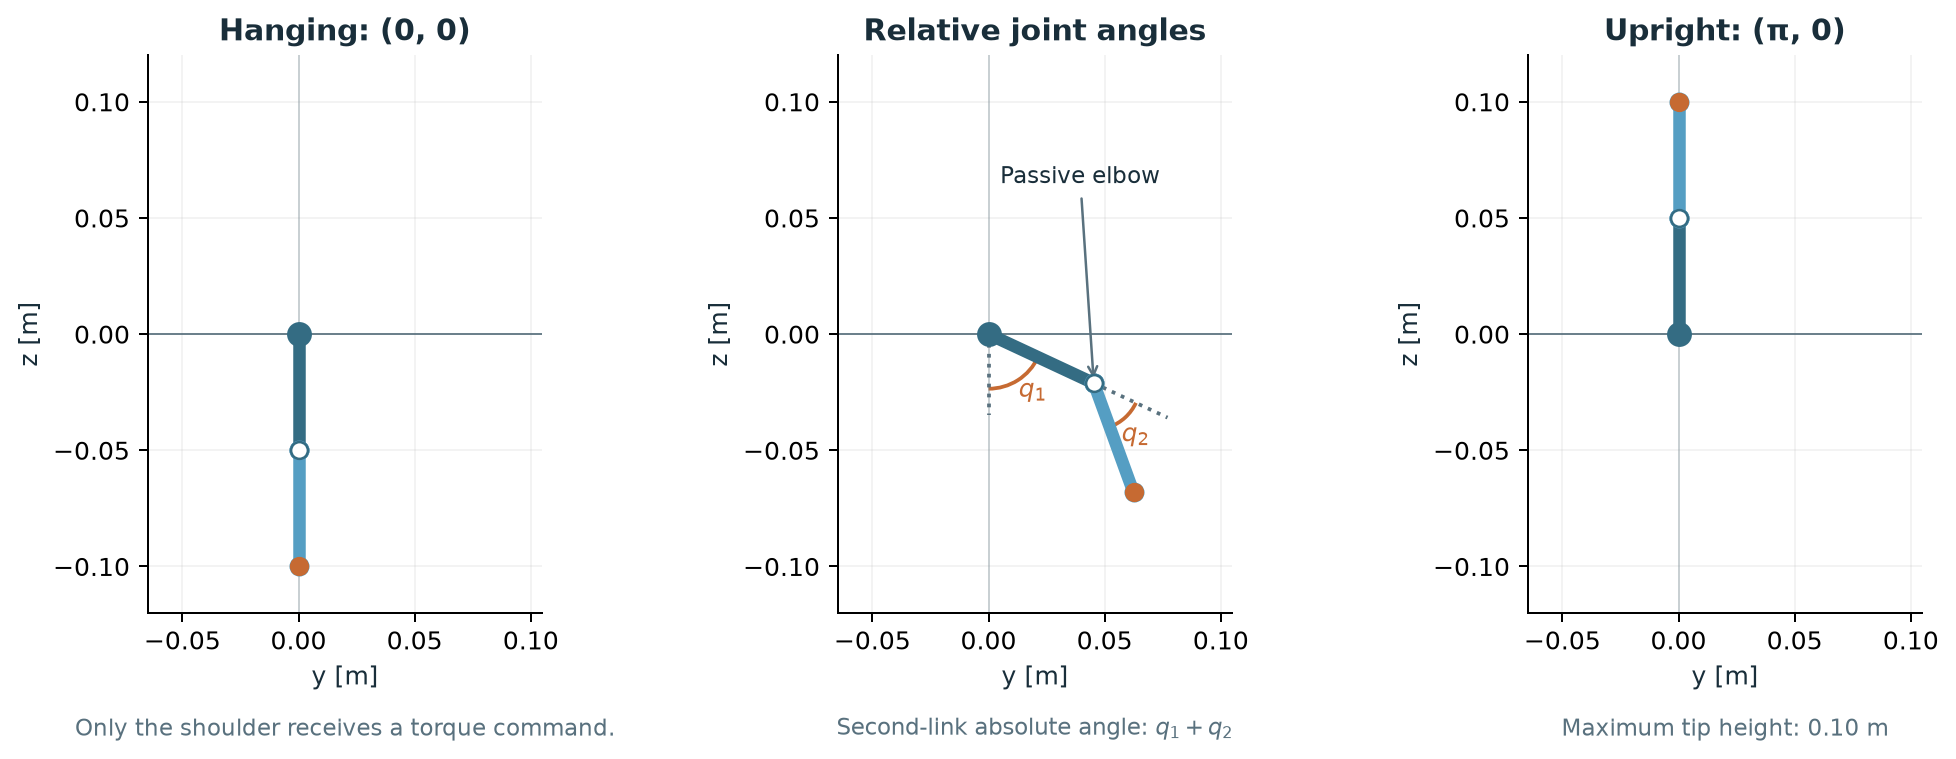

*Figure 1. Start, relative joint coordinates, and upright goal, using the URDF link lengths.*

### Activity 1 — change a joint angle

The helper computes the shoulder, elbow and tip positions in the $y$–$z$ plane.
This is a geometric calculation; no robot is connected.

Change only `q_demo[1]`, the elbow angle, and run the drawing again.
Which point stays fixed? Which link changes its absolute orientation?

In [ ]:
def planar_points(q):
    """Shoulder, elbow and tip in the y-z plane; joint angles are relative."""
    absolute_angles = np.cumsum(q)
    links = LINK_LENGTHS[:, None] * np.column_stack(
        (np.sin(absolute_angles), -np.cos(absolute_angles)))
    return np.vstack((np.zeros(2), np.cumsum(links, axis=0)))

In [ ]:
q_demo = np.deg2rad([60., -40.])  # change the second number, then draw again
points = planar_points(q_demo)

fig, ax = plt.subplots(figsize=(5.5, 4), layout="constrained")
ax.plot(points[:2, 0], points[:2, 1], "o-", lw=5, color="#346c83", label="first link")
ax.plot(points[1:, 0], points[1:, 1], "o-", lw=5, color="#559ec3", label="second link")
ax.scatter(*points[-1], s=65, color="#c66a32", zorder=3, label="tip")
ax.set(xlim=(-.115, .115), ylim=(-.115, .115), aspect="equal",
       xlabel="y [m]", ylabel="z [m]", title="Your chosen configuration")
ax.grid(alpha=.2)
ax.legend()
plt.show()
print("Tip position [y, z] in metres:", points[-1])

<details>
<summary>Discussion hint — relative angles</summary>

Changing only the elbow angle leaves the shoulder and elbow positions fixed.
The second link rotates around the elbow. At $(\pi,\pi)$ the first link points
up and the second points down, so equal-length links put the tip at the base.
The upright target is $(\pi,0)$.

</details>

## 2 · Formulate the motion with inverse dynamics

To plan motion, we need to describe which motions the robot can produce.
The hardware accepts a **shoulder torque**. Our model relates that torque to the
motion of both joints.

### Start from the robot's equations of motion

For this two-joint mechanism,

$$
M(q)\ddot q+h(q,\dot q)=\tau,
\qquad
\tau=\begin{bmatrix}\tau_1\\0\end{bmatrix}.
$$

Here $q=[q_1,q_2]^\mathsf{T}$ contains the joint angles, $M(q)$ is the $2\times2$
inertia matrix, and $h$ contains the modeled gravity and velocity-dependent
terms. The zero in the torque vector means **no motor torque at the elbow**;
the elbow can still accelerate through gravity and coupling with the shoulder.

In a **forward-dynamics** formulation, we choose a shoulder torque and compute
the resulting acceleration:

$$\ddot q=M(q)^{-1}\bigl(\tau-h(q,\dot q)\bigr).$$

### Our choice: plan accelerations, recover torques

This notebook uses an **inverse-dynamics formulation** instead. The optimizer
searches over predicted states $x_k=(q_k,\dot q_k)$ and joint accelerations
$a_k=\ddot q_k$ at each prediction stage $k$. Given a candidate state and
acceleration, inverse dynamics computes the joint torques that motion would
require:

$$\tau_k=\operatorname{ID}(q_k,\dot q_k,a_k)
=M(q_k)a_k+h(q_k,\dot q_k).$$

Why choose accelerations? They give simple equations for propagating the predicted
motion. With prediction step $\Delta t_p$, the model's default **semi-implicit
Euler** integration is

$$
\begin{aligned}
\dot q_{k+1}&=\dot q_k+\Delta t_p\,a_k,\\
q_{k+1}&=q_k+\Delta t_p\,\dot q_{k+1}.
\end{aligned}
$$

These equations link successive predicted states. The nonlinear robot dynamics
now enter through constraints on the **required torques**. This is a choice of
optimization variables; the command sent to the hardware is still a torque.

### Two accelerations, one motor: enforce feasibility

The optimizer cannot choose the two accelerations independently. At every
prediction stage, the inverse-dynamics result must satisfy

$$\tau_{2,k}=0,\qquad |\tau_{1,k}|\leq0.1\,\mathrm{Nm}.$$

In particular, the passive-elbow equation is

$$M_{21}(q_k)a_{1,k}+M_{22}(q_k)a_{2,k}+h_2(q_k,\dot q_k)=0.$$

It couples the two accelerations so that the planned motion needs no elbow
actuator. A candidate requiring nonzero elbow torque is infeasible, even if its
shoulder torque is within bounds.
The URDF also supplies joint-position and velocity bounds; its velocity limit
is $20\,\mathrm{rad/s}$.

At each feedback update, we will take the **first optimized acceleration**,
compute its required torque using the measured state, and send the shoulder
component to the motor. Then we will replan from the next measurement.

> **Check your understanding.** Does a passive elbow mean $a_2=0$?
> Which quantity must actually be zero?

<details>
<summary>Discussion hint — passive does not mean stationary</summary>

The required elbow torque $\tau_2$ must be zero. The elbow acceleration $a_2$
can be nonzero: gravity and the motion of the first link can accelerate it.
The passive-elbow equation determines which acceleration combinations are
physically possible.

</details>

Together, the integration equations and torque constraints define our
inverse-dynamics motion model.

## 3 · Choose costs for swing-up and balance

The dynamics tell us which motions are feasible. **Costs rank those motions**:
they express what we want the controller to accomplish. Keep the physical torque
limits as constraints; use costs for preferences that may need to compete.

### Begin with behavior, before choosing numbers

“Reach upright” is only part of the task. A trajectory can pass through upright
at high speed and immediately fall. We also want to **brake and balance**. At the
same time, a pendubot needs motion to build momentum, so insisting on low speed
throughout the swing can prevent it from getting up.

Start by naming a measurable error for each desired behavior. Here we use tip
position for upward extension, joint velocities for braking, elbow angle for
alignment, and joint accelerations to discourage unnecessarily large acceleration
requests. Each error is a **residual**; the cost penalizes its size. Every added
term should have a behavior you can explain and a tradeoff you can test.

### Four cost terms, four jobs

Our running cost, applied at each prediction stage, is

$$
\ell(x,a)=\frac12\|w_p(p_\mathrm{tip}-p_\mathrm{ref})\|^2
+\frac12\|w_v\dot q\|^2
+\frac12\|w_a a\|^2
+\frac12\|w_e q_2\|^2.
$$

| Term | Residual scale | Intended role | A tradeoff to watch |
|---|---|---|---|
| Tip position | `4.2` | Reward upward extension | A target does not itself guarantee balancing |
| Joint velocity | `0.03` | Discourage fast motion and encourage braking | Too much penalty can suppress momentum buildup |
| Joint acceleration | `0.002` | Regularize the chosen accelerations | This penalizes acceleration, not motor torque |
| Elbow configuration | `2.0` | Prefer a straight elbow | It competes with useful bent configurations during the lift |

Here $p_\mathrm{tip}$ is computed from the predicted joint angles and
$p_\mathrm{ref}$ is the desired Cartesian tip position. The shoulder
configuration scale is zero: upward extension is already encouraged by the tip
term. Acceleration regularization does not directly penalize motor effort or
changes between successive commands.

**Running costs** shape the path throughout the horizon. The **terminal cost**
expresses the preferred state at its end, here using the same tip, velocity and
elbow terms. There is a terminal state $x_H$, but no terminal control $a_H$.
Neither cost forces the robot to be upright at every update: the optimizer may
accept temporary position error or speed to obtain a better predicted trajectory.

> **Predict.** Two trajectories reach the same tip height. One has large joint
> velocities and the other is nearly at rest. Would a tip-position cost alone
> distinguish their ability to catch?

With the roles of all four terms established, let us examine the tip target.

### Why aim the tip above its reachable height?

The two 5 cm links place the upright tip at **0.10 m**. We use a **soft**
Cartesian target $p_\mathrm{ref}=[0,0,0.20]$ m to reward upward extension.
The target contributes a penalty; it is not an equality constraint demanding
an impossible pose.

> **Predict.** Does the unreachable target make the whole problem infeasible?
> What would change if we imposed `tip_height == 0.20` as a hard constraint?

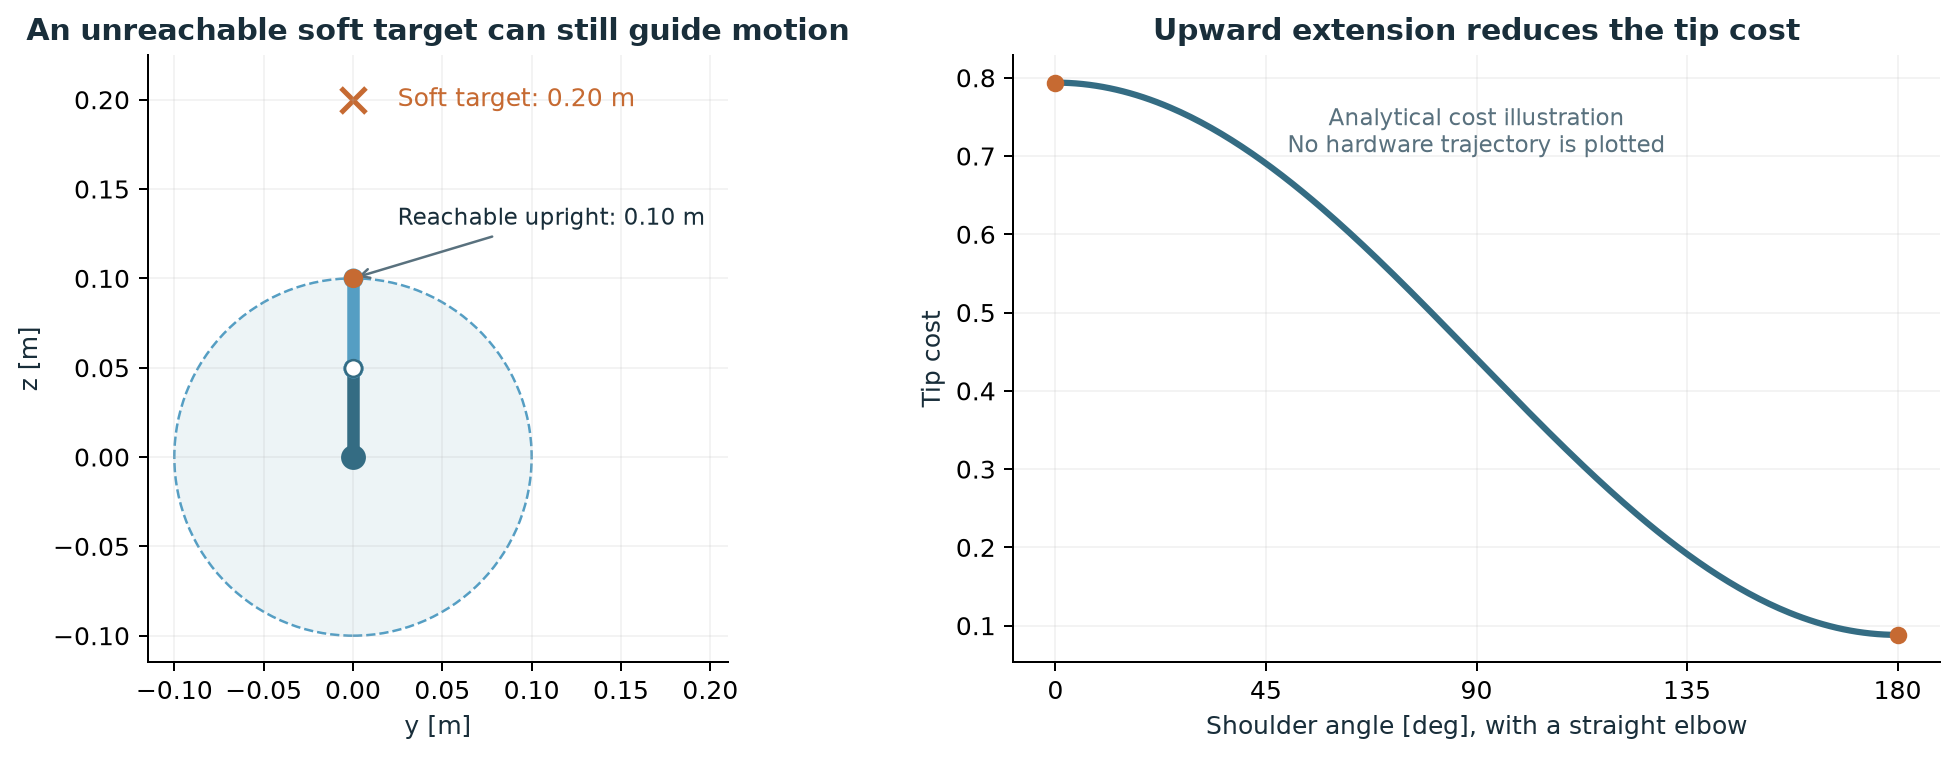

*Figure 2. Reachable tip positions and the soft target. The right panel is an analytical cost illustration, not a robot trajectory.*

In [ ]:
target_yz = np.array([0., 0.20])
for name, q in [
    ("hanging", [0., 0.]),
    ("bent elbow", np.deg2rad([90., -90.])),
    ("upright", [np.pi, 0.]),
]:
    tip_yz = planar_points(q)[-1]
    tip_cost = 0.5 * np.linalg.norm(4.2 * (tip_yz-target_yz))**2
    print(f"{name:12s} | tip height {tip_yz[1]: .3f} m | tip cost {tip_cost:.4f}")

<details>
<summary>Discussion hint — soft target versus feasibility</summary>

A finite penalty guides the optimizer toward upward extension without requiring
the target to be reached. A hard height constraint at 0.20 m would conflict with
this mechanism's geometry. Upright minimizes the tip distance in this illustration,
but successful swing-up also needs dynamically feasible motion, momentum and braking.

</details>

### Choose scales using meaningful errors and priorities

Do not compare the numbers `4.2`, `0.03` and `0.002` on their own. The residuals
have different units and typical magnitudes: metres, radians, rad/s and rad/s².
A small scale multiplying a large residual can still make a substantial cost.

One way to choose an initial scale is to pick a **meaningful error size** $s_i$
for each residual and a relative priority $\alpha_i>0$:

$$\ell_i=\frac{\alpha_i}{2}\left\|\frac{r_i}{s_i}\right\|^2,
\qquad w_i=\frac{\sqrt{\alpha_i}}{s_i}.$$

For a scalar residual of size $s_i$, this gives a penalty $\alpha_i/2$.
It provides an interpretable starting point; observations still determine whether
the balance produces enough momentum and braking. The values in the table are
our baseline, not universal settings for other robots or tasks.

In this notebook, SSQP receives **residual scales**:
$\ell_r=\frac12\|Wr\|^2$. Thus the quadratic coefficient is $w_i^2$, and doubling
a scale multiplies its cost contribution by four. When tuning, compare changes
in residuals and motion as well as the total objective.

> **Predict.** If we change the velocity scale from `0.03` to `0.06`, what happens
> to the velocity cost at the same state?

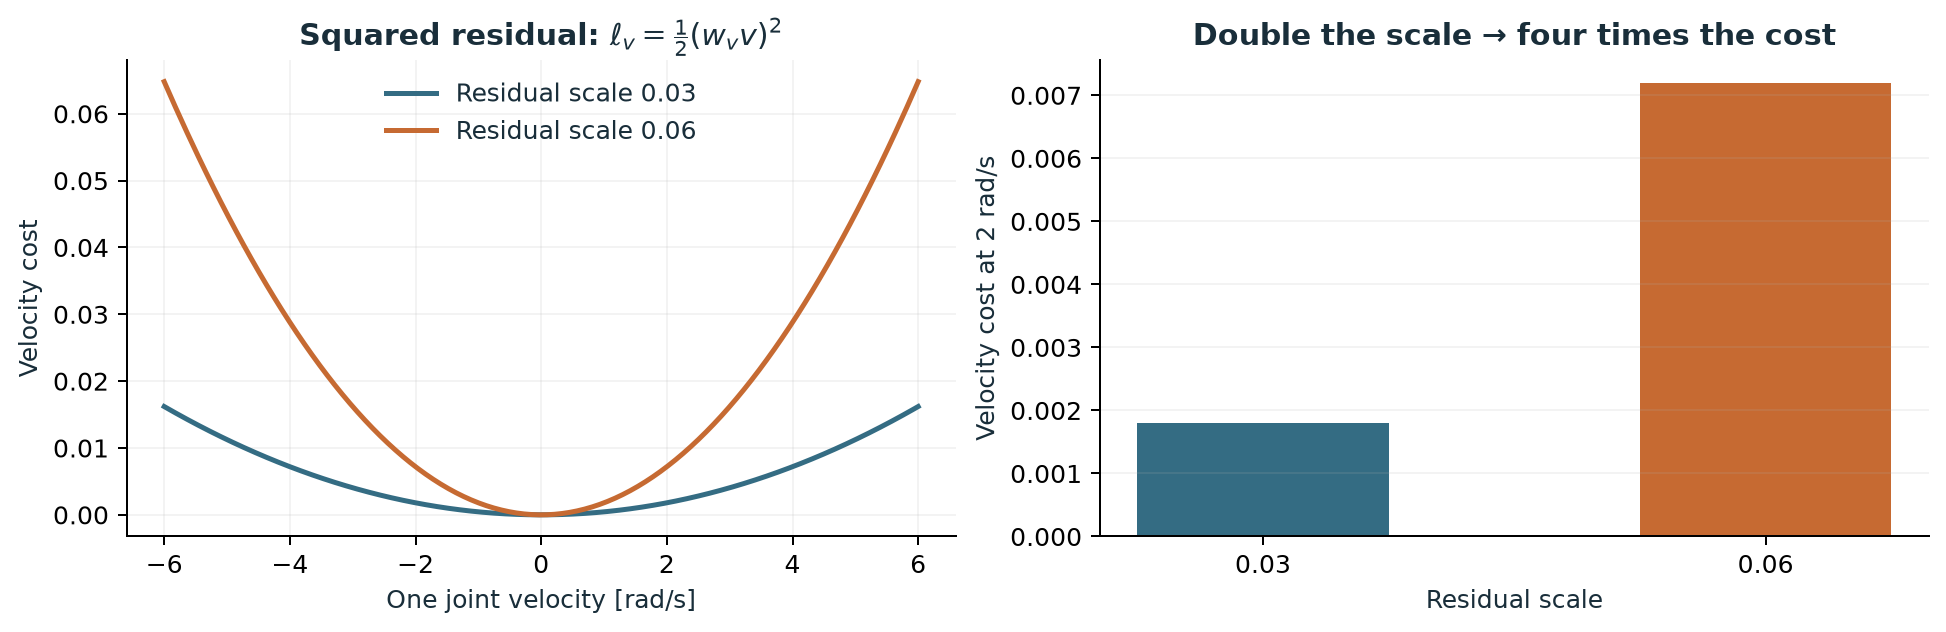

*Figure 3. How a residual scale changes a squared velocity cost; these are analytical values.*

In [ ]:
test_velocity = np.array([2., -1.])  # same state for both comparisons
cost_003 = 0.5 * np.linalg.norm(0.03 * test_velocity)**2
cost_006 = 0.5 * np.linalg.norm(0.06 * test_velocity)**2
print("Velocity costs:", cost_003, cost_006)
print("Cost ratio:", cost_006 / cost_003)

### Turn an observed symptom into one tuning hypothesis

These are hypotheses to test, rather than guaranteed diagnoses:

| Observed behavior | A candidate change | Competing effect to inspect |
|---|---|---|
| Little momentum builds up | Reduce the velocity penalty | Faster motion may make the balancing harder |
| The robot passes upright quickly | Increase the velocity penalty | Earlier braking may prevent a full lift |
| The elbow stays bent near the top/before balancing | Increase the elbow penalty | Straightening too early may hinder swing-up |
| The plan requests large accelerations | Increase the acceleration penalty | Less agility may hurt recovery; torque saturation may remain |

First inspect torque saturation, solver fallbacks and timing too: a cost change
does not fix every cause of poor motion. Change one factor, keep the initial
condition and horizon fixed, then compare lift, catch and hold in the same plots.

In the core exercise we will change only `velocity_weight`. Other cost edits go
in `add_swingup_costs` below; re-run its definition and construct a fresh
controller after editing it. Record those edited scales in your experiment note.

> **Before tuning.** Write: “I will change ___ because I observed ___.
> I expect ___ to improve, but ___ may get worse.”

## 4 · Build the controller in small steps

At each feedback update, solve a finite-horizon optimal control problem:

$$
\begin{aligned}
\min_{x_{0:H},a_{0:H-1}}\quad&
\sum_{k=0}^{H-1}\ell(x_k,a_k)+\phi(x_H)\\
\text{subject to}\quad&
x_0=x_\mathrm{measured},\quad x_{k+1}=f_{\Delta t_p}(x_k,a_k),\\
&\tau_{2,k}=0,\quad |\tau_{1,k}|\leq0.1\,\mathrm{Nm},
\end{aligned}
$$

together with the robot's other innate bounds. The terminal cost is a soft
arrival objective; there is no hard terminal equality forcing upright.

We will construct the model, attach costs, choose solver settings, and assemble
the feedback policy. The helper functions below are ordinary Python definitions
in this notebook. You can read and edit each part directly.

### Step A — load the mechanism and choose the control meaning

`actuated_joints=[0]` selects the shoulder. In `InverseDynamics` mode, SSQP
optimizes accelerations and constrains their required torques using the robot
description. Two acceleration controls do not give us two motors.

Run the function definition and inspection cell. The model is not yet finalized
for optimization; we will attach its costs first.

In [ ]:
# Install ssqp if not already installed
import sys
!{sys.executable} -m pip install ssqp

In [ ]:
import ssqpy
from pycloudpendulumbenchmark import ControllerBase, MotorState
ssqpy.setSilentMode()
print("SSQP module:", ssqpy.__file__)

In [ ]:
def build_pendubot_model(horizon=20, dt=0.01):
    return ssqpy.model.Model(
        horizon, dt, urdf_path=URDF_PATH,
        actuated_joints=[0],
        solver_mode=ssqpy.model.SolverMode.InverseDynamics,
    )

In [ ]:
model = build_pendubot_model(horizon=20)
print("Configuration, velocity and acceleration sizes:",
      model.getnq(), model.getnv(), model.getnu())
print("Expected for this robot: 2, 2, 2")

### Step B — attach running and terminal costs

There are $H$ control stages, numbered `0` through `H-1`, and $H+1$ states,
numbered `0` through `H`. The terminal stage is `H`.

Read the two loops carefully. The acceleration cost belongs only to running
stages. The tip, velocity and elbow costs also apply at the terminal state.

> **Explain.** Why does the last loop omit the acceleration cost?

In [ ]:
def add_swingup_costs(model, horizon, velocity_weight=0.03):
    # These numbers are residual scales: cost = 0.5 * ||scale * error||^2.
    velocity = ssqpy.model.costs.SquaredJointVelocityCost(model, velocity_weight)
    acceleration = ssqpy.model.costs.SquaredControlCost(model, 0.002)
    tip = ssqpy.model.costs.FrameSquaredTranslationErrorCost(
        model, "tip", np.array([0., 0., 0.20]), 4.2)
    elbow = ssqpy.model.costs.SquaredConfigurationErrorCost(
        model, np.array([np.pi, 0.]), np.array([0., 2.]))
    for k in range(horizon):
        for cost in (velocity, acceleration, tip, elbow):
            model.addCost(k, cost)
    # There is a terminal state, but no terminal control.
    for cost in (velocity, tip, elbow):
        model.addCost(horizon, cost)

In [ ]:
add_swingup_costs(model, horizon=20, velocity_weight=0.03)
print("Running and terminal costs added. Next: build the MPC solver.")

### Step C — distinguish the nonlinear solve from the QP solve

**SQP** means sequential quadratic programming. At the current trajectory,
linearize the constraints, form a local quadratic problem, solve it for a
correction, and test an update. Neighboring stages are coupled by dynamics;
SSQP uses this structure in the linear algebra.

The **QP backend** solves one local quadratic problem inside each SQP
correction. Here it is ADMM. Its tolerances and iteration limit are different
from the nonlinear solver's tolerance and correction budget.

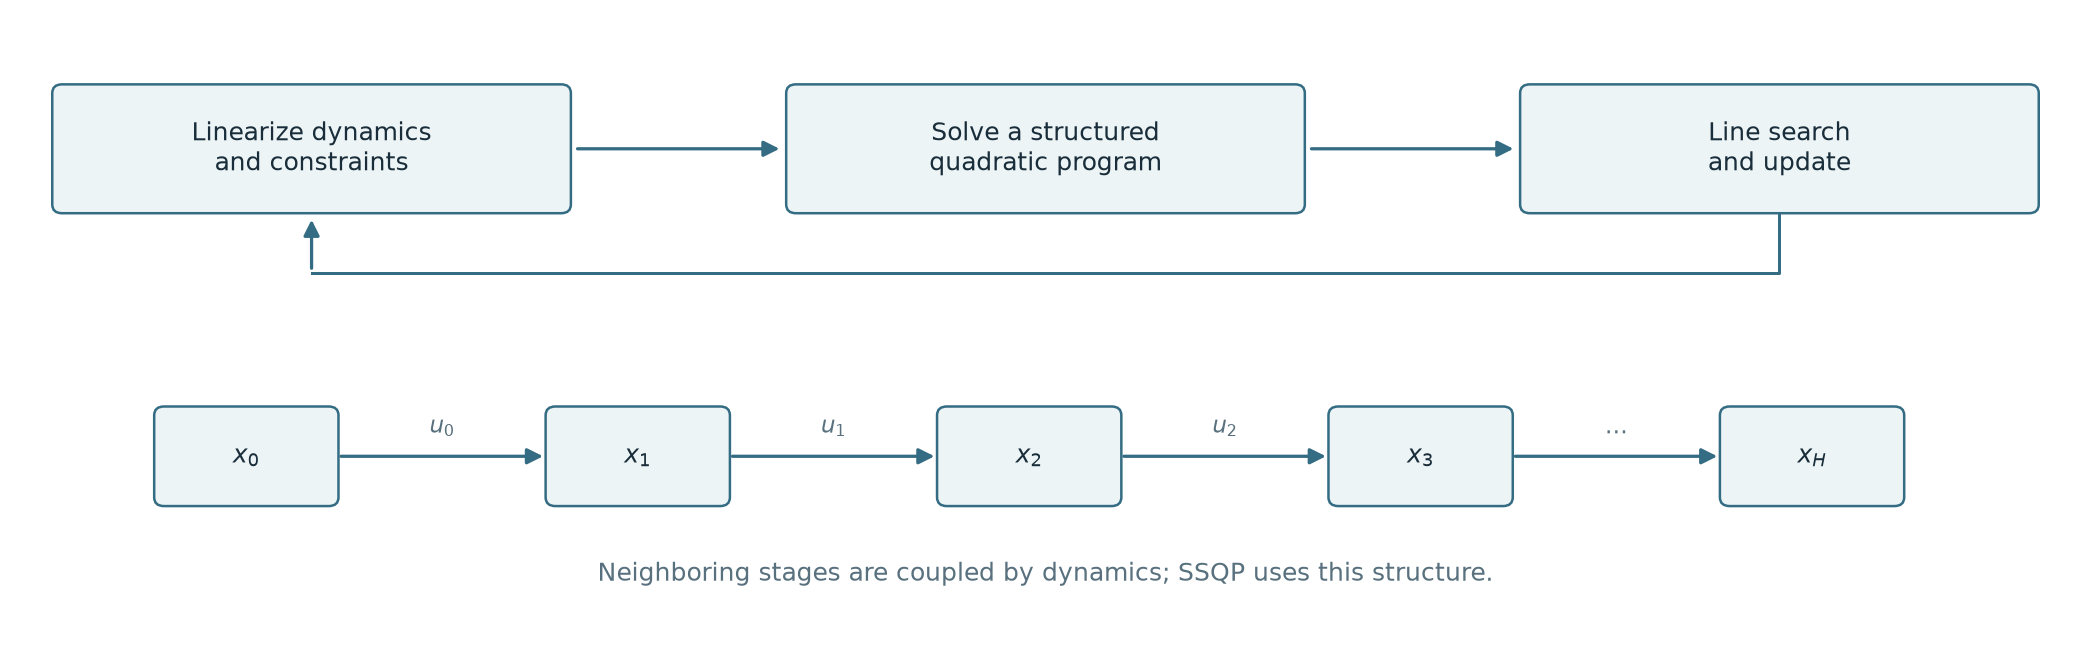

*Figure 4. Local SQP corrections and the chain of neighboring prediction stages.*

In [ ]:
def build_mpc(model, sqp_iters=4):
    params = ssqpy.solvers.ssqpParams()
    params.tolerance = 0.1
    qp_params = ssqpy.solvers.admmParams()
    qp_params.abs_tolerance = 0.01
    qp_params.rel_tolerance = 0.01
    qp_params.warm_start = True
    params.admmParams = qp_params
    return ssqpy.solvers.MPC(model, params, sqp_iters=sqp_iters, qp_iters=100)

In [ ]:
mpc = build_mpc(model)
print("MPC constructed; the model is finalized with its costs.")
print("Per update: at most 4 SQP corrections, up to 100 QP iterations each.")

### Step D — separate prediction time from feedback time

The prediction grid uses $\Delta t_p=10$ ms and $H=20$, giving 0.20 s of
look-ahead. The requested feedback interval is $\Delta t_c=1$ ms.

The prediction grid sets model resolution and problem size. The feedback request
sets how frequently we ask for a new command. They need not be equal.
A request of 1 ms is not evidence that the full feedback cycle achieves 1 ms;
we will measure its timing.

Use the first predicted acceleration to compute the torque for the current
update, then replan from new measurements. We do not wait for a complete
10 ms prediction stage before asking for another command.

> **Predict.** At a fixed prediction step, how much look-ahead does `horizon=30`
> give? Which computational work grows?

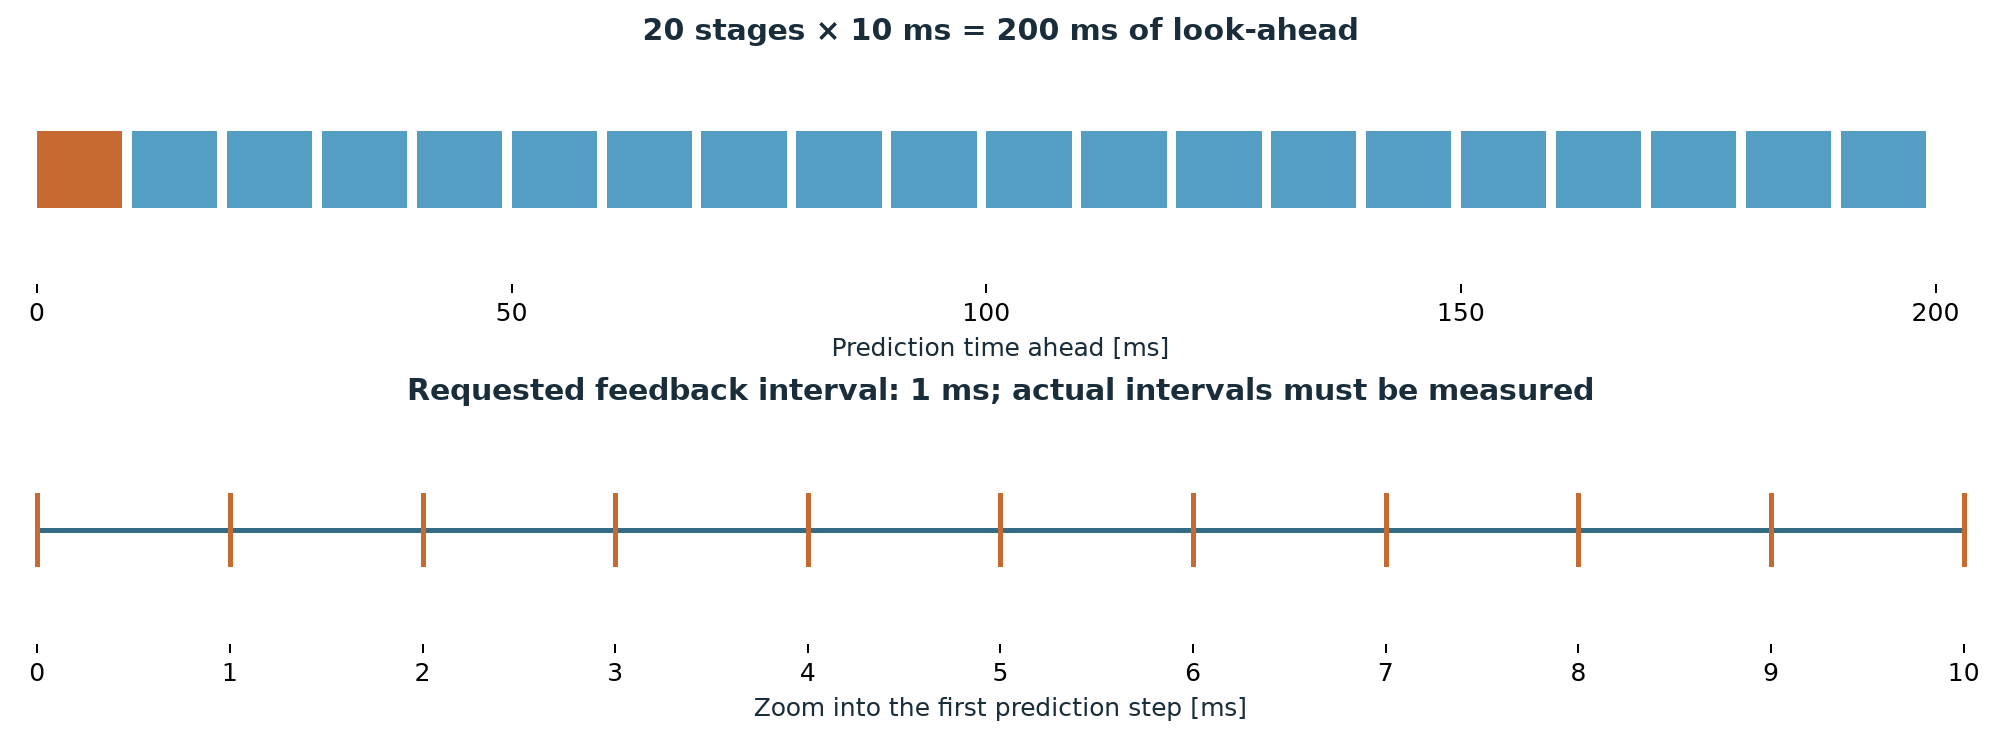

*Figure 5. The 200 ms prediction horizon and a zoom showing the 1 ms requested feedback interval.*

In [ ]:
prediction_dt = 0.01
for horizon in (20, 30):
    print(f"{horizon} stages: {horizon*prediction_dt:.2f} s look-ahead, "
          f"{horizon+1} states and {horizon} controls.")

### Step E — assemble the policy that returns one motor command

The class below reuses the three construction functions we have examined.
In each callback it:

1. Forms the state as `[q1, q2, velocity1, velocity2]`.
2. Calls `mpc.step` using the measured state and takes the first acceleration.
3. Converts the acceleration to joint torques through inverse dynamics.
4. Clips the command and returns **one element**, `[torque[0]]`.

The passive-elbow condition belongs in the optimization model. Sending only one
torque and clipping it cannot, by themselves, make arbitrary accelerations feasible.

If the solver raises `RuntimeError`, the fallback requests zero acceleration and
converts it to torque. This is a gravity/velocity compensation request, not
necessarily zero motor torque. We count these fallbacks during experiments.

In [ ]:
class PendubotMPC(ControllerBase):
    def __init__(self, horizon=20, velocity_weight=0.03, sqp_iters=4):
        self.dt = 0.01
        self.torque_clip = 0.1
        self.solver_failures = 0
        self.settings = dict(horizon=horizon, velocity_weight=velocity_weight, sqp_iters=sqp_iters)
        self.model = build_pendubot_model(horizon, self.dt)
        self.nq = self.model.getnq()
        self.nv = self.model.getnv()
        self.nu = self.model.getnu()
        add_swingup_costs(self.model, horizon, velocity_weight)
        self.mpc = build_mpc(self.model, sqp_iters)

    def get_control_output(self, state):
        q = np.array([motor.position for motor in state])
        v = np.array([motor.velocity for motor in state])
        try:
            acceleration = self.mpc.step(np.hstack((q, v)))[1].stage(0)
        except RuntimeError:
            self.solver_failures += 1
            acceleration = np.zeros(self.nv)
        torque = self.model.inverseDynamics(q, v, acceleration)
        torque = np.clip(torque, -self.torque_clip, self.torque_clip)
        return [torque[0]]

### Check the assembled controller before a trial

Construct the complete controller and check native kinematics. This does not
start a hardware experiment.

**Expected checks:** configuration/velocity/control sizes `2, 2, 2`;
0.20 s look-ahead; hanging/upright tip heights $-0.10/0.10$ m.
Compare the solver's kinematics with your earlier planar drawing.

In [ ]:
controller = PendubotMPC()
print("Configuration / velocity / control sizes:", controller.nq, controller.nv, controller.nu)
print("Look-ahead [s]:", controller.settings["horizon"]*controller.dt)
for name, q in [("hanging", [0., 0.]), ("upright", [np.pi, 0.])]:
    tip_xyz = controller.model.forwardKinematics(np.array(q), "tip")[0]
    print(name, "tip [x,y,z]:", tip_xyz)
    np.testing.assert_allclose(tip_xyz[1:], planar_points(q)[-1], atol=1e-10)
print("Settings:", controller.settings)

## 5 · Close the loop on CloudPendulum

A motion plan becomes feedback when fresh measurements change the next plan.
MPC updates the initial state, reuses the previous trajectory as a warm start,
and performs a limited correction before returning the next command.

Follow the signal path in Figure 6. **Point to where acceleration becomes torque.**
Then locate the same operation in `get_control_output`.

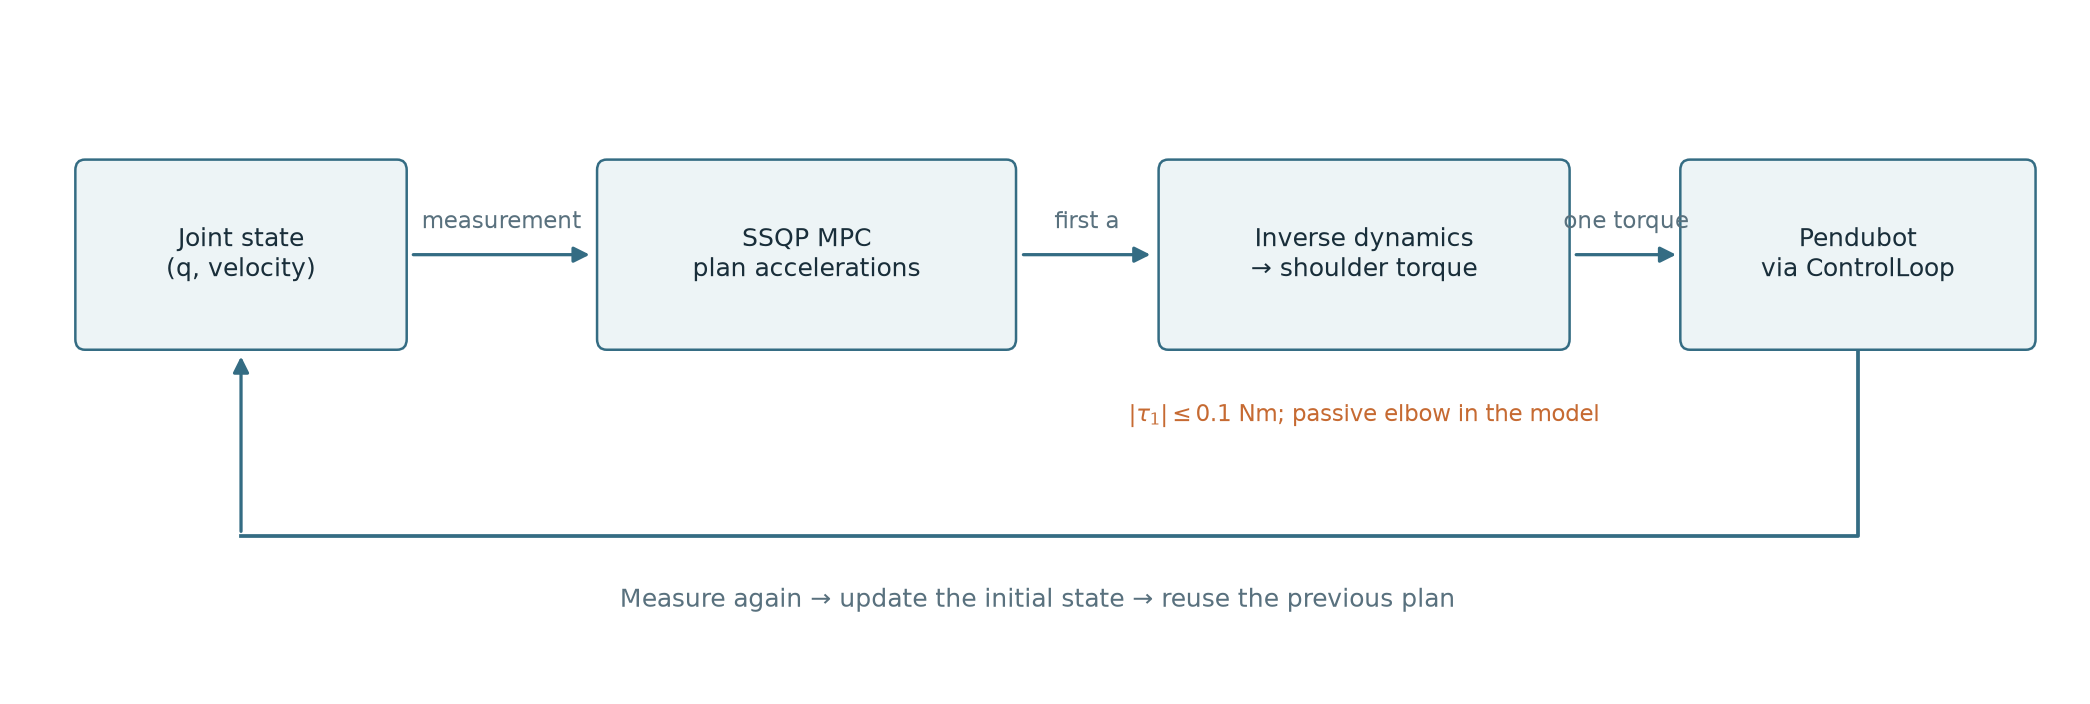

*Figure 6. Measurement, acceleration planning, torque conversion and the next feedback update.*

### Configure the experiment once

Use your assigned robot cell and token file. Each trial starts hanging down,
lasts 20 s, and requests no injected disturbances by default. Section 8 adds
a scheduled disturbance through the same runner.

Keep the `trials` list between runs so the baseline remains available.
Re-running this settings cell resets that list; for tuning, re-run only
the trial, plotting and comparison cells below.

In [ ]:
from pycloudpendulumbenchmark import ControlLoop
from pycloudpendulumbenchmark.evaluators import GoalHeightEvaluator

CELL_ID = 203                    # replace with your assigned cell
TOKEN_PATH = Path("token.txt")   # your CloudPendulum token file
EXPERIMENT_TIME = 20.0
LOOP_DT = 0.001
trials = []

### What the runner records

The runner measures → computes a command → scores the state/command → sends
the command. `ControlLoop` supplies the robot interface; `GoalHeightEvaluator`
supplies the platform score. The `finally` block stops a started experiment
even if the callback fails.

The optional `disturbances` argument is passed to the server when the experiment
starts. Omit it for the baseline. If the platform returns disturbance logs from
`stop()`, the runner retains and prints them alongside the recording link.

Each logged row contains:

| Field | Meaning |
|---|---|
| Experiment time | Timestamp reported by the platform loop |
| Four state values | Two joint angles, then two velocities |
| Shoulder torque | Command returned by the controller |
| Callback time | MPC, inverse dynamics and clipping |
| Loop-body time | State access, callback, scoring and command transmission; excludes the final log append |

Run this definition once. Focus on the controller during the core route;
revisit the logging details in a longer session.

In [ ]:
def run_trial(controller, label, disturbances=None):
    evaluator = GoalHeightEvaluator()
    token = TOKEN_PATH.read_text().splitlines()[0].strip()
    control_loop = ControlLoop(
        cell_id=CELL_ID,
        initial_position=np.array((0.0, 0.0)),
        disturbances=[] if disturbances is None else list(disturbances),
        dt=LOOP_DT,
        user_token=token,
        experiment_time=EXPERIMENT_TIME,
        experiment_type="Pendubot",
    )
    rows = []
    started = False
    video_url = None
    disturbance_logs = None
    try:
        control_loop.start()
        started = True
        while not control_loop.finished():
            cycle_start = perf_counter()
            state = control_loop.get_state()
            experiment_t = control_loop.time()
            q = [motor.position for motor in state]
            v = [motor.velocity for motor in state]

            callback_start = perf_counter()
            output = controller.get_control_output(state)
            callback_s = perf_counter() - callback_start
            evaluator.evaluate(state, output, experiment_t)
            control_loop.step(output)
            cycle_s = perf_counter() - cycle_start

            rows.append((experiment_t, q + v, float(output[0]), callback_s, cycle_s))
    finally:
        if started:
            stopped = control_loop.stop()
            # Some platform builds return (video URL, server logs).
            if isinstance(stopped, tuple) and len(stopped) == 2:
                video_url, disturbance_logs = stopped
            else:
                video_url = stopped

    score = evaluator.get_score()
    print("Score:", score)
    print("Solver fallbacks:", controller.solver_failures)
    if video_url:
        print("Recording:", video_url)
    if disturbance_logs:
        print("Server disturbance logs:", disturbance_logs)
    return dict(label=label, settings=controller.settings.copy(), rows=rows,
                score=score, solver_failures=controller.solver_failures,
                disturbance_logs=disturbance_logs)

### Baseline trial — predict before running

**Write a prediction:** will the default controller lift, catch, and hold?
Which plot distinguishes “reaches upright once” from “balances upright”?

When ready for your assigned cell, set `RUN_HARDWARE=True` below.
Start with `PendubotMPC()` unchanged. Each execution creates a fresh controller,
so warm-start history is not carried from one trial to another.

Inspect the recording and plots before changing a parameter.

In [ ]:
RUN_HARDWARE = False

if RUN_HARDWARE:
    controller = PendubotMPC()  # change only this line for a tuning trial
    trials.append(run_trial(controller, label=f"trial_{len(trials)+1:02d}"))
else:
    print("Hardware is disabled. Set RUN_HARDWARE=True when ready for the assigned cell.")

## 6 · Read motion and timing together

A score summarizes an experiment, but does not explain its mechanism.
Read the six plots as evidence:

1. **Tip height:** does the robot lift and remain near the upright height?
2. **Goal errors:** does it catch both joints near $(\pi,0)$?
3. **Velocities:** does it brake, or pass upright with too much speed?
4. **Shoulder torque:** does it spend long periods at the command limit?
5. **Computation time:** do callback or loop-body times exceed the requested interval?
6. **Logged intervals:** how regularly are updates recorded?

The angle plot wraps errors into $[-\pi,\pi]$. A jump at the wrap boundary can
be a plotting effect; it does not alter the state passed to the solver.
Tip height is computed from logged joint angles and the URDF geometry.

A high fallback count means the policy often used the compensation fallback,
which can change the motion even when every returned torque is finite.

Run the plotting definitions once, then re-run the short plotting cell after
each experiment. Plots use **your logged data**, not a pre-filled swing-up trace.

In [ ]:
def trial_arrays(trial):
    rows = trial["rows"]
    return (
        np.array([row[0] for row in rows]),
        np.array([row[1] for row in rows]),
        np.array([row[2] for row in rows]),
        1000*np.array([row[3] for row in rows]),
        1000*np.array([row[4] for row in rows]),
    )

In [ ]:
def plot_trial(trial):
    if not trial["rows"]:
        print("This trial has no logged samples.")
        return
    t, x, torque, callback_ms, cycle_ms = trial_arrays(trial)
    error = np.arctan2(np.sin(x[:, :2]-[np.pi, 0.]), np.cos(x[:, :2]-[np.pi, 0.]))
    tip_height = -LINK_LENGTHS[0]*np.cos(x[:, 0])-LINK_LENGTHS[1]*np.cos(x[:, 0]+x[:, 1])
    fig, axes = plt.subplots(3, 2, figsize=(11.5, 9), layout="constrained")
    axes[0, 0].plot(t, tip_height, color="#346c83")
    axes[0, 0].axhline(sum(LINK_LENGTHS), color="#c66a32", ls="--", label="upright height")
    axes[0, 0].set(ylabel="Tip height [m]", title="1 / Lift and hold")
    axes[0, 0].legend(fontsize=8)
    axes[0, 1].plot(t, error[:, 0], label="shoulder")
    axes[0, 1].plot(t, error[:, 1], label="elbow")
    axes[0, 1].set(ylabel="Wrapped goal error [rad]", title="2 / Catch the upright pose")
    axes[0, 1].legend(fontsize=8)
    axes[1, 0].plot(t, x[:, 2], label="shoulder")
    axes[1, 0].plot(t, x[:, 3], label="elbow")
    axes[1, 0].set(ylabel="Velocity [rad/s]", title="3 / Build momentum, then brake")
    axes[1, 0].legend(fontsize=8)
    axes[1, 1].plot(t, torque, color="#346c83")
    for bound in (-0.1, 0.1):
        axes[1, 1].axhline(bound, color="#c66a32", ls="--")
    axes[1, 1].set(ylabel="Shoulder torque [Nm]", title="4 / Inspect command saturation")
    axes[2, 0].plot(t, callback_ms, label="controller callback")
    axes[2, 0].plot(t, cycle_ms, label="loop body", alpha=.7)
    axes[2, 0].axhline(1000*LOOP_DT, color="#c66a32", ls="--", label="requested interval")
    axes[2, 0].set(ylabel="Computation time [ms]", title="5 / Measure computation")
    axes[2, 0].legend(fontsize=8)
    if len(t)>1:
        axes[2, 1].plot(t[1:], 1000*np.diff(t), ".", ms=2, color="#346c83")
    axes[2, 1].axhline(1000*LOOP_DT, color="#c66a32", ls="--", label="requested interval")
    axes[2, 1].set(ylabel="Logged interval [ms]", title="6 / Check the actual cadence")
    axes[2, 1].legend(fontsize=8)
    for ax in axes.flat:
        ax.set_xlabel("Experiment time [s]")
        ax.grid(alpha=.2)
    fig.suptitle(f"{trial['label']} — {trial['settings']}", fontsize=12)
    plt.show()

In [ ]:
if trials and trials[-1]["rows"]:
    plot_trial(trials[-1])
else:
    print("No measured data yet. Run a baseline to populate these plots.")

> **Explain your baseline.** Identify one interval of momentum buildup and one
> of braking in the recording and plots. Does high tip position coincide with
> low joint errors and low velocities? Which timing measurement is closest
> to the requested 1 ms interval?

<details>
<summary>Discussion hint — motion, computation and cadence</summary>

A momentary high tip position is not the same as catching and holding upright.
Use joint errors, velocities and the recording together. Callback duration
omits parts of the loop; even loop-body duration omits the final log append.
Logged timestamp intervals separately measure cadence. Report distributions
and their tails, rather than claiming a feedback rate from one fast callback.

</details>

## 7 · Change one cause, then compare the evidence

Choose **one** trial and predict its effect before running it.

| Trial | Replace only the constructor line with | Prediction to test |
|---|---|---|
| A: stronger velocity penalty | `controller = PendubotMPC(velocity_weight=0.06)` | Does balancing improve, or does momentum buildup suffer? |
| B: longer horizon | `controller = PendubotMPC(horizon=30)` | Does 0.30 s look-ahead improve the catch, and what is its computation cost? |

For A, velocity cost is four times larger at the same state.
For B, keep the 10 ms step fixed. More stages add variables, constraints and
running-cost terms, and change their balance with the terminal cost.

1. Record your prediction in the response cell below.
2. Return to the **baseline trial cell**, edit one constructor line, and run it.
3. Re-run the **plotting** and **comparison** cells; retain the earlier trial in `trials`.
4. Assess the built-in score, motion, fallbacks, torque and timing together.

Return to `PendubotMPC()` before comparing another change against the default.

### Your experiment note — edit this Markdown cell

- **Changed parameter:** …
- **Prediction before running:** …
- **What changed in lift / catch / hold:** …
- **What changed in timing and fallbacks:** …
- **Evidence supporting the explanation:** …
- **Next single change to investigate:** …

In [ ]:
def compare_trials(trials):
    valid = [trial for trial in trials if trial["rows"]]
    if not valid:
        print("No experiment data yet. Run a baseline, then one changed setting.")
        return
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), layout="constrained")
    for trial in valid:
        t, x, torque, callback_ms, cycle_ms = trial_arrays(trial)
        tip_height = -LINK_LENGTHS[0]*np.cos(x[:, 0])-LINK_LENGTHS[1]*np.cos(x[:, 0]+x[:, 1])
        axes[0].plot(t, tip_height, label=trial["label"])
        ordered = np.sort(callback_ms)
        axes[1].step(ordered, np.arange(1, len(ordered)+1)/len(ordered), where="post", label=trial["label"])
        print(trial["label"], trial["settings"], "score:", trial["score"])
        print("  fallbacks:", trial["solver_failures"], "peak torque [Nm]:", np.max(np.abs(torque)))
        print("  callback p50/p95/max [ms]:", np.percentile(callback_ms, [50, 95, 100]))
        print("  loop body p50/p95/max [ms]:", np.percentile(cycle_ms, [50, 95, 100]))
        if len(t)>1:
            print("  logged interval p50/p95/max [ms]:", np.percentile(1000*np.diff(t), [50, 95, 100]))
    axes[0].axhline(sum(LINK_LENGTHS), color=".5", ls="--", label="upright height")
    axes[0].set(xlabel="Experiment time [s]", ylabel="Tip height [m]", title="Compare the motion")
    axes[1].axvline(1000*LOOP_DT, color="#c66a32", ls="--", label="requested interval")
    axes[1].set(xlabel="Controller callback time [ms]", ylabel="Fraction of samples ≤ time",
                title="Compare timing, including the tails", ylim=(0, 1.02))
    for ax in axes:
        ax.legend(fontsize=8)
        ax.grid(alpha=.2)
    plt.show()

In [ ]:
def save_trial(trial):
    if not trial["rows"]:
        return
    t, x, torque, callback_ms, cycle_ms = trial_arrays(trial)
    # Save numerical results only; never the token or the recording URL.
    np.savez(trial["label"]+".npz", t=t, x=x, torque=torque,
             callback_ms=callback_ms, cycle_ms=cycle_ms,
             settings_json=json.dumps(trial["settings"]),
             disturbance_json=json.dumps(trial.get("disturbance_spec")))

In [ ]:
compare_trials(trials)
for trial in trials:
    save_trial(trial)

### Read the timing distribution

The comparison plot shows the empirical cumulative distribution of callback
times. At time $t$ on the horizontal axis, the curve gives the fraction completed
within $t$. A curve reaching 1 farther right has a slower worst observed callback.
Printed p50, p95 and maximum values quantify the median and the tail.

The comparison cell saves `trial_01.npz`, `trial_02.npz`, and so on.
These contain numerical states, torques, timings, controller settings and any
scheduled-pulse specification,
without the token or recording URL.

## 8 · Inject a disturbance and test recovery

Reaching upright once does not establish disturbance recovery. We will run the
same controller twice: first without a disturbance, then with one scheduled
shoulder-torque pulse. Each run starts hanging down with a fresh controller.
Keep costs, horizon, initial condition and requested feedback interval identical.

This activity uses the [CloudPendulum disturbance tutorial](https://github.com/cloudpendulum/tutorial_disturbance_injection/blob/c5b3dceefd56653fe342dcccc5ec653e019f1792/tutorial_disturbance_api.ipynb).
We adapt its torque-disturbance API to our pendubot and MPC controller.

### Schedule one shoulder-torque pulse

The default pulse begins at **8 s**, lasts **75 ms**, and adds **0.02 Nm** at the
shoulder. It has one torque value because this robot has one actuator.
Use your baseline plots to choose a time after the catch. If the robot has not
balanced before the pulse, this tests disturbed swing-up rather than recovery
from balance.

The server applies the extra torque; our MPC keeps using its nominal model
and responds through subsequent state measurements:

$$M(q)\ddot q+h(q,\dot q)
=\begin{bmatrix}\tau_\mathrm{command}+d(t)\\0\end{bmatrix}.$$

Run the settings cell once. Its plot shows the **planned injection**, not a
measured robot response; it does not connect to the hardware.

In [ ]:
PULSE_SPEC = dict(start_time=8.0, duration=0.075, torque=[0.1, 0.])
DISTURBANCE_CONTROLLER = dict(horizon=20, velocity_weight=0.03, sqp_iters=4)
disturbance_pair = []

pulse_start = PULSE_SPEC["start_time"]
pulse_end = pulse_start + PULSE_SPEC["duration"]
assert 0 < pulse_start < pulse_end < EXPERIMENT_TIME

fig, ax = plt.subplots(figsize=(8, 2.6), layout="constrained")
ax.step([pulse_start-.25, pulse_start, pulse_end, pulse_end+.25],
        [0., PULSE_SPEC["torque"][0], 0., 0.], where="post", color="#c66a32")
ax.set(xlabel="Experiment time [s]", ylabel="Extra shoulder torque [Nm]",
       title="Planned disturbance schedule — no hardware response shown")
ax.grid(alpha=.2)
plt.show()

### Predict, then run the matched pair

**Predict:** which state changes first after a torque pulse: position or velocity?
Will the controller correct the deviation without falling, or need another swing-up?
What competing effect might a stronger velocity penalty have?

The next cell runs **two 20 s experiments** when enabled. It reuses your assigned
`CELL_ID` and `TOKEN_PATH`. The kernel must provide `pycloudpendulum`, as in the
linked tutorial. `TimedTorqueDisturbance` is passed directly to `ControlLoop`;
we continue sending the controller's ordinary one-element torque command.

Set the separate `RUN_DISTURBANCE_ROLLOUT` switch to `True` when ready.
Each execution appends both runs to `trials`. Re-run the rollout and analysis
cells to repeat the comparison; re-running the settings cell clears
`disturbance_pair`.

In [ ]:
RUN_DISTURBANCE_ROLLOUT = False

if RUN_DISTURBANCE_ROLLOUT:
    from pycloudpendulum import TimedTorqueDisturbance

    # Constructor order: time after start, duration, one torque per actuator.
    pulse = TimedTorqueDisturbance(
        PULSE_SPEC["start_time"], PULSE_SPEC["duration"], PULSE_SPEC["torque"])
    disturbance_pair = []
    reference = run_trial(PendubotMPC(**DISTURBANCE_CONTROLLER),
                          label=f"pulse_reference_{len(trials)+1:02d}")
    trials.append(reference)
    disturbed = run_trial(PendubotMPC(**DISTURBANCE_CONTROLLER),
                          label=f"pulse_injected_{len(trials)+1:02d}",
                          disturbances=[pulse])
    disturbed["disturbance_spec"] = dict(PULSE_SPEC, torque=list(PULSE_SPEC["torque"]))
    trials.append(disturbed)
    disturbance_pair = [reference, disturbed]
else:
    print("Disturbance rollout is disabled. Set RUN_DISTURBANCE_ROLLOUT=True when ready.")

### Inspect the recovery, not just the final height

The comparison marks the **scheduled pulse window** on both runs. Confirm actual
injection using the server disturbance logs, when returned by the platform,
and the recording. A requested schedule alone does not prove that it was applied.
The command plot shows what our controller returned; it excludes the injected
torque, so it is not a measurement of the total applied torque.

For an explicit evaluation rule, call the state “in tolerance” when **both**
wrapped joint errors are at most **0.15 rad** and both speeds at most
**1 rad/s**. The helper reports the time after the scheduled pulse ends until
the logged states have stayed within these thresholds for **1 s**. This time
includes that confirmation interval. These thresholds evaluate the result;
they do not change the controller or impose a terminal constraint.

If no such interval is recorded, report “not confirmed” rather than assigning
a recovery time. Inspect timestamp gaps and the recording too: the hold test
only sees the logged samples. A state already in tolerance still needs the
1 s confirmation interval.

In [ ]:
def plot_disturbance_rollout(reference, disturbed, angle_tol=0.15, speed_tol=1.0, hold_seconds=1.0):
    if not reference["rows"] or not disturbed["rows"]:
        print("Both trials need logged samples before comparing recovery.")
        return {}
    pulse = disturbed["disturbance_spec"]
    start = pulse["start_time"]
    end = start + pulse["duration"]
    fig, axes = plt.subplots(2, 2, figsize=(11.5, 7), layout="constrained")
    confirmations = {}
    for trial, color in ((reference, "#346c83"), (disturbed, "#c66a32")):
        t, x, torque, _, _ = trial_arrays(trial)
        error = np.arctan2(np.sin(x[:, :2]-[np.pi, 0.]), np.cos(x[:, :2]-[np.pi, 0.]))
        max_error = np.max(np.abs(error), axis=1)
        max_speed = np.max(np.abs(x[:, 2:]), axis=1)
        height = -LINK_LENGTHS[0]*np.cos(x[:, 0])-LINK_LENGTHS[1]*np.cos(x[:, 0]+x[:, 1])
        for ax, values in zip(axes.flat, (height, max_error, max_speed, torque)):
            ax.plot(t, values, color=color, label=trial["label"])

        # A sample-based hold test; report elapsed time including confirmation.
        in_bounds = (max_error <= angle_tol) & (max_speed <= speed_tol)
        hold_start = None
        confirmed_after = None
        for sample_t, ok in zip(t, in_bounds):
            if sample_t < end:
                continue
            if not ok:
                hold_start = None
            else:
                if hold_start is None:
                    hold_start = sample_t
                if sample_t - hold_start >= hold_seconds:
                    confirmed_after = float(sample_t - end)
                    break
        confirmations[trial["label"]] = confirmed_after
        result = (f"{confirmed_after:.3f} s" if confirmed_after is not None
                  else "not confirmed in the recorded post-pulse interval")
        print(f"{trial['label']}: time after pulse end to confirm {hold_seconds:g} s in tolerance: {result}")

    axes[0, 0].axhline(sum(LINK_LENGTHS), color=".5", ls="--")
    axes[0, 0].set(title="Lift and recover", ylabel="Tip height [m]")
    axes[0, 1].axhline(angle_tol, color=".5", ls="--")
    axes[0, 1].set(title="Both joints near upright", ylabel="Largest absolute joint error [rad]")
    axes[1, 0].axhline(speed_tol, color=".5", ls="--")
    axes[1, 0].set(title="Brake and hold", ylabel="Largest absolute joint velocity [rad/s]")
    for bound in (-0.1, 0.1):
        axes[1, 1].axhline(bound, color=".5", ls="--")
    axes[1, 1].set(title="Controller command (injected torque excluded)", ylabel="Shoulder command [Nm]")
    for ax in axes.flat:
        ax.axvspan(start, end, color="#c66a32", alpha=.2, label="scheduled pulse window")
        ax.axvline(start, color="#c66a32", ls=":", lw=1)
        ax.set_xlabel("Experiment time [s]")
        ax.grid(alpha=.2)
    axes[0, 0].legend(fontsize=8)
    plt.show()
    return confirmations

In [ ]:
if len(disturbance_pair) == 2:
    recovery_times = plot_disturbance_rollout(*disturbance_pair)
    compare_trials(disturbance_pair)
    for trial in disturbance_pair:
        save_trial(trial)
else:
    print("Run the matched reference/pulse pair to populate the recovery comparison.")

> **Explain the evidence.** Was the pendubot balanced before the pulse? Did it
> recover directly, re-swing, or fail to catch again? Compare joint errors and
> velocities with the reference, then inspect saturation, fallbacks and timing.

- **Observed behavior before the pulse:** …
- **Evidence that injection occurred:** …
- **Recovery behavior and time including confirmation:** …
- **Difference from the reference and a plausible explanation:** …
- **Next single change to test:** …

For a follow-up, reverse the pulse direction while keeping its timing, duration
and controller fixed. Predict whether recovery will be symmetric before running.

Further reading: [disturbance API](https://cloudpendulum.m2.chalmers.se/docs/generated/cloudpendulumclient.disturbance.html),
[SSQP](https://lar.upatras.gr/ssqp/), and
[the MPC interface](https://lar.upatras.gr/ssqp/concepts/mpc/).